In [1]:
import os
import numpy as np
import librosa
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Verificar si hay GPU disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: cuda


## Hacemos la descarga los de los archivo .wav separados por carpeta segun el genero

In [2]:
# import gdown
# import zipfile
# import os

# url = "https://drive.google.com/uc?id=1txyVxGVezQ4fcHqFi-n3gcWKEYQexu1_"
# output = "dataset_music.zip"

# gdown.download(url, output, quiet=False)

# destino = "datos_music"
# os.makedirs(destino, exist_ok=True)

# with zipfile.ZipFile(output, "r") as zip_ref:
#     zip_ref.extractall(destino)

# DATASET_PATH = "/content/datos_music/genres_original"

### Vamos a separar los archivos de cada estilo musical en un 70/15/15 por canción (train/val/test)

In [3]:
import os
import glob
from sklearn.model_selection import train_test_split

#DATASET_PATH = "content/datos_music/genres_original"
DATASET_PATH = r"C:\content\datos_music\genres_original"


# 1. Ruta a tu carpeta principal que contiene las subcarpetas con géneros
data_dir = DATASET_PATH # Cambia esto por tu ruta real

audio_paths = []
labels = []
class_names = sorted(os.listdir(data_dir))
class_to_idx = {class_name: i for i, class_name in enumerate(class_names)}

print(f"Géneros detectados: {class_names}")

# 2. Recorrer las subcarpetas y recolectar todas las rutas de archivos .wav y sus etiquetas
for genre in class_names:
    genre_path = os.path.join(data_dir, genre)
    if os.path.isdir(genre_path):
        # Buscar todos los archivos .wav en la carpeta del género
        wav_files = glob.glob(os.path.join(genre_path, "*.wav"))
        for file in wav_files:
            audio_paths.append(file)
            labels.append(class_to_idx[genre])

print(f"Total de archivos encontrados: {len(audio_paths)}")

# 3. Partición 70% train / 15% val / 15% test, estratificada y POR CANCIÓN (archivo completo),
#    así ningún fragmento de una misma canción puede caer en dos conjuntos distintos (sin fuga de datos).
#    Val se usa para elegir el mejor modelo; test solo se usa una vez al final.
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    audio_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print(f"Archivos de Entrenamiento: {len(train_paths)}")
print(f"Archivos de Validación: {len(val_paths)}")
print(f"Archivos de Test: {len(test_paths)}")

Géneros detectados: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']
Total de archivos encontrados: 999
Archivos de Entrenamiento: 699
Archivos de Validación: 150
Archivos de Test: 150


# EDA y preprocesamiento del dataset

* Los archivos tienen alrededor de 30 segundos. Muchos de los segmentos de audio de generos populares parecen iniciar ~ 10 segundos
antes del estribillo. Los estribillos suelen estar compuestos de varias repeticiones del mismo audio, lo cual podria ser negativo
para el modelo.

* Limitar la frecuencia de muestreo a 22050 Hz significa descartar el espectro de audio por sobre 11025 Hz.

    * Eso descarta informacion (armonicos de los tonos de varios instrumentos) que podria servir para clasificar generos, pero trae 
    el beneficio de aliviar la carga computacional.

* Con audio re-sampleado a 22050 Hz y una fft de 2048 puntos, la resolucion espectral resulta 10,77 Hz, lo cual podria ser 
innecesariamente angosto ya que la frecuencia mas baja del piano La0 es 27.5 Hz (casi al limite del rango auditivo), 
con lo cual una resolucion de 30 Hz ya segregaria bastante bien los armonicos en distintos bins (fft de 1024 puntos).

* Dejamos la ventana por defecto de la libreria (Hanning) ya que reduce el leakage entre bins de la fft (buena discriminacion)
sin perder resolucion en frecuencia.

* Las muestras son de 30 segundos. Dado que tenemos que clasificar entre generos de mucica occidental, 30 segundos da una buena
chance de capturar mas de 1 seccion de la estructur de la cancion (intro, verso, coro, puente, etc) lo cual podria ayudar
en la deteccion. Por otro lado, en 30 segundos de audio podria haber secciones repetidas que resulten en informacion redundante, 
o impacten negativamente en la capacidad de generalizacion del modelo. 
    * Luego de varias pruebas se cortan 3 segmentos del audio original: 0-3s, 13.5-16.5s, 27-30s, se les aplica una ventana Hanning para evitar agregar componentes de alta frecuencia sintéticas y se concatenan las muestras para quedarnos con 1 muestra de 9 s por canción. Ésto debería capturar las distintas secciónes sin incluir repeticiones del estribillo.

* El parametro hop length es el salto en cantidad de muestras entre una fft y la siguiente. Para fs = 22050 Hz, cada muestra
representa 45 $\mu$ s. Asignamos el valor 256 (solapamiento del 25 % de las muestras) para dar saltos de 11 ms. Esto tambien define
la cantidad de frames. Para 10 segundos de audio, se obtienen 860 frames, con lo cual se le da al parametro max_time_frames el
valor 860 para evitar que la libreria rellene con 0.


In [4]:
from tqdm import tqdm
import numpy as np
import librosa
import torch
from torch.utils.data import Dataset

class MusicGenreDataset(Dataset):
    #def __init__(self, audio_paths, labels, sr=22050, duration=30, n_mels=128, max_time_frames=1300):
    # Cada canción de 30 s aporta UN ejemplo: 3 trozos de 3 s (inicio, medio y final), cada uno multiplicado por una
    # ventana de Hann y concatenados (9 s). A 22050 Hz con hop 256 -> 777 frames.
    def __init__(self, audio_paths, labels, sr=22050, seg_duration=3, n_segments=3, n_mels=128, max_time_frames=None):
        self.audio_paths = audio_paths
        self.labels = labels
        self.sr = sr
        self.seg_duration = seg_duration
        self.n_segments = n_segments
        self.n_mels = n_mels
        if max_time_frames is None:
            max_time_frames = int(seg_duration * n_segments * sr / 256) + 1
        self.max_time_frames = max_time_frames

        # Inicializar listas para almacenar en memoria RAM
        self.cached_specs = []
        self.cached_labels = []
        self.errores = 0

        print(f"⏳ Pre-calculando y cargando {len(audio_paths)} audios en memoria RAM...")
        for idx in tqdm(range(len(self.audio_paths))):
            audio_path = self.audio_paths[idx]
            label = self.labels[idx]

            seg_len = int(self.seg_duration * self.sr)
            try:
                # Cargar la canción completa (30 s) y calcular los puntos de inicio de los trozos:
                # el primero al inicio, el último al final y los intermedios repartidos uniformemente
                y, sr_loaded = librosa.load(audio_path, sr=self.sr)
                if len(y) < seg_len:
                    y = np.pad(y, (0, seg_len - len(y)))
                starts = np.linspace(0, len(y) - seg_len, self.n_segments).astype(int)
                # Ventana de Hann en cada trozo (fade in/out) para suavizar las uniones al concatenar
                ventana = np.hanning(seg_len)
                seg = np.concatenate([y[s:s + seg_len] * ventana for s in starts])

                # Extraer el espectrograma de Mel
                mel_spec = librosa.feature.melspectrogram(y=seg, sr=sr_loaded, n_fft=1024, hop_length=256, n_mels=self.n_mels)
                mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)

                # Normalización estándar (Z-score)
                mel_spec_db = (mel_spec_db - mel_spec_db.mean()) / (mel_spec_db.std() + 1e-6)

                # Ajustar longitud temporal (Padding / Truncate)
                current_frames = mel_spec_db.shape[1]
                if current_frames < self.max_time_frames:
                    mel_spec_db = np.pad(mel_spec_db, ((0, 0), (0, self.max_time_frames - current_frames)), mode='constant')
                else:
                    mel_spec_db = mel_spec_db[:, :self.max_time_frames]

                spec = torch.tensor(mel_spec_db, dtype=torch.float32).unsqueeze(0) # [1, n_mels, time_frames]

            except Exception as e:
                # En caso de un error de lectura, usar un tensor de ceros para evitar detener el entrenamiento
                self.errores += 1
                print(f"Error leyendo {audio_path}: {e}")
                spec = torch.zeros((1, self.n_mels, self.max_time_frames), dtype=torch.float32)

            self.cached_specs.append(spec)
            self.cached_labels.append(torch.tensor(label, dtype=torch.long))

        print("✅ ¡Todos los espectrogramas han sido pre-calculados con éxito en RAM!")

    def __len__(self):
        return len(self.cached_specs)

    def __getitem__(self, idx):
        # Retorno inmediato ultra-eficiente desde la memoria
        return self.cached_specs[idx], self.cached_labels[idx]

def predecir(modelo, loader):
    """Predicciones del modelo sobre un loader (un ejemplo por canción). Devuelve (y_true, y_pred)."""
    modelo.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for inputs, labels in loader:
            outputs, _ = modelo(inputs.to(device))
            y_pred.extend(outputs.argmax(1).cpu().numpy())
            y_true.extend(labels.numpy())
    return np.array(y_true), np.array(y_pred)

In [5]:
class TemporalAttention(nn.Module):
    def __init__(self, hidden_dim):
        super(TemporalAttention, self).__init__()
        self.attention_weights = nn.Linear(hidden_dim, 1)

    def forward(self, rnn_out):
        # rnn_out shape: [Batch, Time_Frames, Hidden_Dim]
        scores = self.attention_weights(rnn_out) # [Batch, Time_Frames, 1]
        weights = F.softmax(scores, dim=1)        # [Batch, Time_Frames, 1]

        # Suma ponderada temporal (Context Vector)
        context_vector = torch.sum(rnn_out * weights, dim=1) # [Batch, Hidden_Dim]
        return context_vector, weights

class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Conexión residual si el número de canales cambia
        self.shortcut = nn.Sequential()
        if in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out

class ImprovedMusicGenreCRNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3, rnn_type='LSTM'):
        super(ImprovedMusicGenreCRNN, self).__init__()

        # Extractor Convolucional Mejorado con Bloques Residuales y Dropout
        # Canales reducidos (16-32-64-128) para un modelo más chico acorde a pocas muestras,
        # y Dropout2d más suave (0.1 en las primeras capas, 0.2 en las profundas).
        self.layer1 = ConvBlock(1, 16)
        self.pool1 = nn.MaxPool2d((2, 2))  # 128 -> 64
        self.drop1 = nn.Dropout2d(0.1)

        self.layer2 = ConvBlock(16, 32)
        self.pool2 = nn.MaxPool2d((2, 2))  # 64 -> 32
        self.drop2 = nn.Dropout2d(0.1)

        self.layer3 = ConvBlock(32, 64)
        self.pool3 = nn.MaxPool2d((2, 2))  # 32 -> 16
        self.drop3 = nn.Dropout2d(0.2)

        self.layer4 = ConvBlock(64, 128)
        self.pool4 = nn.MaxPool2d((2, 2))  # 16 -> 8
        self.drop4 = nn.Dropout2d(0.2)

        # Entrada a la RNN: 128 canales * 8 frecuencias
        self.rnn_input_size = 128 * 8

        # Red recurrente bidireccional de 2 capas: RNN clásica (activación tanh) o LSTM.
        # La LSTM usa internamente sigmoid (compuertas) y tanh (estado de celda); la RNN clásica usa tanh,
        # que mantiene el estado acotado en [-1, 1] y evita que explote en secuencias largas.
        rnn_cls = {'RNN': nn.RNN, 'LSTM': nn.LSTM}[rnn_type]
        rnn_kwargs = {'nonlinearity': 'tanh'} if rnn_type == 'RNN' else {}
        self.rnn = rnn_cls(
            input_size=self.rnn_input_size,
            hidden_size=128,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=dropout,
            **rnn_kwargs
        )

        # Mecanismo de atención temporal
        self.attention = TemporalAttention(hidden_dim=256)

        # Clasificador final robusto con Dropout
        self.fc = nn.Sequential(
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        # x shape: [Batch, 1, 128, Time_Frames]
        batch_size = x.size(0)

        # Feature Extraction con CNN
        x = self.drop1(self.pool1(self.layer1(x)))
        x = self.drop2(self.pool2(self.layer2(x)))
        x = self.drop3(self.pool3(self.layer3(x)))
        x = self.drop4(self.pool4(self.layer4(x)))

        # Reordenar dimensiones para la RNN
        x = x.permute(0, 3, 1, 2) # [Batch, Reduced_Time, 128, 8]
        x = x.reshape(batch_size, x.size(1), -1) # [Batch, Reduced_Time, 128 * 8]

        # Procesamiento temporal con LSTM
        rnn_out, _ = self.rnn(x) # [Batch, Reduced_Time, 256]

        # Capa de Atención temporal
        context_vector, attention_weights = self.attention(rnn_out)

        # Clasificación
        out = self.fc(context_vector)
        return out, attention_weights

In [6]:
# --- CONFIGURACIÓN REAL CON TUS ARCHIVOS .WAV ---

# 1. Crear los Datasets usando los splits 70/15/15 (por canción) que hicimos antes.
#    Un ejemplo por canción: 3 trozos de 3 s (0-3 s, 13.5-16.5 s, 27-30 s) con ventana de Hann, concatenados.
train_dataset = MusicGenreDataset(audio_paths=train_paths, labels=train_labels)
val_dataset = MusicGenreDataset(audio_paths=val_paths, labels=val_labels)
test_dataset = MusicGenreDataset(audio_paths=test_paths, labels=test_labels)

# 2. Crear los DataLoaders (shufle=True solo para entrenamiento)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=8, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=8, shuffle=False, num_workers=0)

# 3. Instanciar modelo, función de pérdida y optimizador
num_genres = len(class_names)  # Se adapta automáticamente a cuántas carpetas/géneros tengas


print(f"¡Modelo inicializado con éxito para {num_genres} géneros: {class_names}!")
print(f"Lotes de entrenamiento: {len(train_loader)} | Validación: {len(val_loader)} | Test: {len(test_loader)}")

⏳ Pre-calculando y cargando 699 audios en memoria RAM...


100%|██████████| 699/699 [00:20<00:00, 33.67it/s]


✅ ¡Todos los espectrogramas han sido pre-calculados con éxito en RAM!
⏳ Pre-calculando y cargando 150 audios en memoria RAM...


100%|██████████| 150/150 [00:03<00:00, 43.44it/s]


✅ ¡Todos los espectrogramas han sido pre-calculados con éxito en RAM!
⏳ Pre-calculando y cargando 150 audios en memoria RAM...


100%|██████████| 150/150 [00:03<00:00, 42.88it/s]

✅ ¡Todos los espectrogramas han sido pre-calculados con éxito en RAM!
¡Modelo inicializado con éxito para 10 géneros: ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']!
Lotes de entrenamiento: 88 | Validación: 19 | Test: 19


## Entrenamiento

* Se corre el entrenamiento con distintas semillas para poder realizar una comparación de los modelos con mas sustento estdístico

* Se utiliza LR adaptativo con valores razonables para deep learning según nuestra experiencia. Iniciando en 0.001 y baja a la mitad si los resultados se aplanan por 3 épocas de paciencia. No usamos early stopping

In [7]:
import time
import random
import pandas as pd
from sklearn.metrics import f1_score, accuracy_score

def entrenar_modelo(rnn_type, pesos, num_epochs=40, lr=1e-3, weight_decay=1e-4):
    """Entrena desde cero un modelo con la recurrencia indicada ('RNN' o 'LSTM') y devuelve (modelo, historial)."""
    # Modelo, loss, optimizador y scheduler nuevos en cada corrida (sin arrastrar pesos previos)
    model = ImprovedMusicGenreCRNN(num_classes=num_genres, dropout=0.3, rnn_type=rnn_type).to(device)
    criterio = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

    best_val_accuracy = 0.0
    hist = {k: [] for k in ['train_loss', 'val_loss', 'train_acc', 'val_acc', 'train_f1', 'val_f1']}
    print(f"🚀 Entrenando {rnn_type} por {num_epochs} épocas...")

    for epoch in range(num_epochs):
        start_time = time.time()

        # 1. FASE DE ENTRENAMIENTO
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0
        train_preds, train_true = [], []
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs, _ = model(inputs)
            loss = criterio(outputs, labels)
            loss.backward()
            # Gradient clipping para estabilizar el entrenamiento de la red recurrente
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            predicted = outputs.argmax(1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
            train_preds.extend(predicted.cpu().numpy())
            train_true.extend(labels.cpu().numpy())

        epoch_train_loss = running_loss / total_train
        epoch_train_acc = 100 * correct_train / total_train
        epoch_train_f1 = 100 * f1_score(train_true, train_preds, average='macro')

        # 2. FASE DE VALIDACIÓN
        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        val_preds, val_true = [], []
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs, _ = model(inputs)
                loss = criterio(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                predicted = outputs.argmax(1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()
                val_preds.extend(predicted.cpu().numpy())
                val_true.extend(labels.cpu().numpy())

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = 100 * correct_val / total_val
        epoch_val_f1 = 100 * f1_score(val_true, val_preds, average='macro')

        for k, v in zip(hist.keys(), [epoch_train_loss, epoch_val_loss, epoch_train_acc, epoch_val_acc, epoch_train_f1, epoch_val_f1]):
            hist[k].append(v)

        scheduler.step(epoch_val_loss)
        current_lr = optimizer.param_groups[0]['lr']

        print(f"[{rnn_type}] Época [{epoch+1}/{num_epochs}] ({time.time() - start_time:.1f}s) | LR: {current_lr:.6f} | "
              f"Train Loss: {epoch_train_loss:.4f} - Train Acc: {epoch_train_acc:.2f}% | "
              f"Val Loss: {epoch_val_loss:.4f} - Val Acc: {epoch_val_acc:.2f}%")

        # Guardar el mejor modelo según accuracy de validación
        if epoch_val_acc > best_val_accuracy:
            best_val_accuracy = epoch_val_acc
            torch.save(model.state_dict(), pesos)
            print(f"   ⭐ ¡Nuevo mejor modelo guardado! (Val Acc: {epoch_val_acc:.2f}%)")

    print(f"\n✨ {rnn_type} finalizado. Mejor precisión en validación: {best_val_accuracy:.2f}%\n")
    return model, hist

def fijar_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

# Entrenar ambos modelos con la misma configuración (solo cambia la recurrencia) y repetir con varias seeds
SEEDS = [0, 1, 2, 3, 4]
tipos = [('RNN clásica', 'RNN'), ('LSTM', 'LSTM')]
runs = {nombre: [] for nombre, _ in tipos}  # por modelo: lista de dicts {seed, pesos, hist, model}
for seed in SEEDS:
    for nombre, tipo in tipos:
        fijar_seed(seed)
        pesos = f"mejor_modelo_{tipo.lower()}_seed{seed}.pth"
        print(f"===== {nombre} | seed {seed} =====")
        m, hist = entrenar_modelo(tipo, pesos)
        runs[nombre].append({'seed': seed, 'pesos': pesos, 'hist': hist, 'model': m})

# Resumen por seed y media ± desviación estándar (validación y test, con los mejores pesos de cada corrida)
filas = []
for nombre, lista in runs.items():
    for r in lista:
        r['model'].load_state_dict(torch.load(r['pesos'], map_location=device))
        yt, yp = predecir(r['model'], val_loader)
        r['val_acc'] = 100 * accuracy_score(yt, yp)
        r['val_f1'] = 100 * f1_score(yt, yp, average='macro')
        yt, yp = predecir(r['model'], test_loader)
        r['test_acc'] = 100 * accuracy_score(yt, yp)
        filas.append({'Modelo': nombre, 'Seed': r['seed'], 'Acc val (%)': r['val_acc'],
                      'F1 macro val (%)': r['val_f1'], 'Acc test (%)': r['test_acc']})
tabla_seeds = pd.DataFrame(filas)
display(tabla_seeds.round(2))
resumen_seeds = tabla_seeds.drop(columns='Seed').groupby('Modelo').agg(['mean', 'std']).round(2)
print(f"Media y desviación estándar sobre {len(SEEDS)} seeds:")
display(resumen_seeds)

# Para los análisis siguientes (curvas, atención, errores, matrices) se usa la primera seed de cada modelo
modelos = {n: l[0]['model'] for n, l in runs.items()}
historiales = {n: l[0]['hist'] for n, l in runs.items()}
pesos_modelos = {n: l[0]['pesos'] for n, l in runs.items()}
model = modelos['LSTM']

===== RNN clásica | seed 0 =====
🚀 Entrenando RNN por 40 épocas...
[RNN] Época [1/40] (5.7s) | LR: 0.001000 | Train Loss: 2.2547 - Train Acc: 15.59% | Val Loss: 2.1050 - Val Acc: 24.67%
   ⭐ ¡Nuevo mejor modelo guardado! (Val Acc: 24.67%)
[RNN] Época [2/40] (3.0s) | LR: 0.001000 | Train Loss: 2.0371 - Train Acc: 27.32% | Val Loss: 1.8671 - Val Acc: 36.00%
   ⭐ ¡Nuevo mejor modelo guardado! (Val Acc: 36.00%)
[RNN] Época [3/40] (3.0s) | LR: 0.001000 | Train Loss: 1.9174 - Train Acc: 32.05% | Val Loss: 1.9956 - Val Acc: 26.00%
[RNN] Época [4/40] (3.0s) | LR: 0.001000 | Train Loss: 1.8556 - Train Acc: 36.91% | Val Loss: 1.7615 - Val Acc: 39.33%
   ⭐ ¡Nuevo mejor modelo guardado! (Val Acc: 39.33%)
[RNN] Época [5/40] (3.1s) | LR: 0.001000 | Train Loss: 1.7420 - Train Acc: 40.06% | Val Loss: 1.6311 - Val Acc: 45.33%
   ⭐ ¡Nuevo mejor modelo guardado! (Val Acc: 45.33%)
[RNN] Época [6/40] (2.9s) | LR: 0.001000 | Train Loss: 1.7183 - Train Acc: 43.49% | Val Loss: 1.5452 - Val Acc: 51.33%
   ⭐ ¡N

,Modelo,Seed,Acc val (%),F1 macro val (%),Acc test (%)
0,RNN clásica,0,72.67,72.74,72.00
1,RNN clásica,1,75.33,75.15,76.67
2,RNN clásica,2,64.00,63.80,64.67
3,RNN clásica,3,74.67,74.22,76.00
4,RNN clásica,4,68.67,67.56,68.67
5,LSTM,0,72.00,71.27,72.00
6,LSTM,1,70.00,69.11,69.33
7,LSTM,2,68.00,67.43,77.33
8,LSTM,3,70.00,69.10,70.67
9,LSTM,4,72.00,71.75,74.00


Media y desviación estándar sobre 5 seeds:


Acc val (%)       F1 macro val (%)       Acc test (%)      
                   mean   std             mean   std         mean   std
Modelo                                                                 
LSTM              70.40  1.67            69.73  1.77        72.67  3.13
RNN clásica       71.07  4.73            70.69  4.84        71.60  5.05

In [8]:
# --- EVALUACIÓN FINAL EN TEST (usar una sola vez, con el mejor modelo de cada tipo según validación) ---
for nombre in modelos:
    m = modelos[nombre]
    m.load_state_dict(torch.load(pesos_modelos[nombre], map_location=device))
    m.eval()

    y_true, y_pred = predecir(m, test_loader)
    correct_test = int((y_true == y_pred).sum())
    total_test = len(y_true)

    print(f"🎯 {nombre} - Accuracy en TEST: {100 * correct_test / total_test:.2f}% ({correct_test}/{total_test})")

🎯 RNN clásica - Accuracy en TEST: 72.00% (108/150)
🎯 LSTM - Accuracy en TEST: 72.00% (108/150)


## Gráficos de atención para LSTM

* Esto puede ayudar a interpretar por qué el modelo acierta o se equivoca

🔄 Cargando los mejores pesos del modelo LSTM ('mejor_modelo_lstm_seed0.pth')...
⏳ Evaluando el set de validación (esto puede tomar un momento en CPU)...

🎯 Precisión Total en Validación: 72.00% (108/150 canciones correctas)

📊 DETALLE DE CANCIONES Y SUS GRÁFICOS DE ATENCIÓN:

🎵 Canción 1:
   • Género Real:    jazz
   • Género Predicho: jazz
   • Resultado:      ¡Correcto! ✅


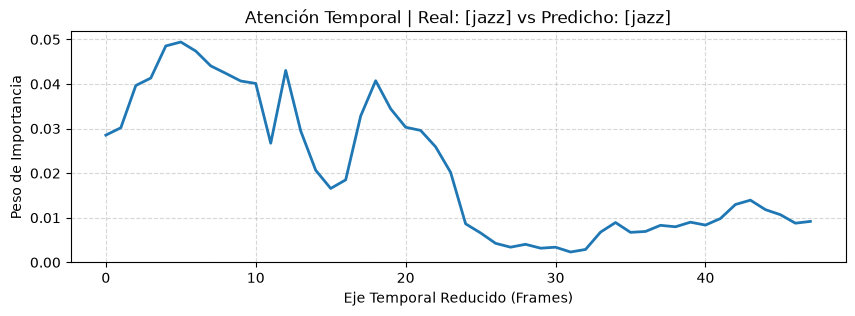


🎵 Canción 2:
   • Género Real:    rock
   • Género Predicho: jazz
   • Resultado:      Incorrecto ❌


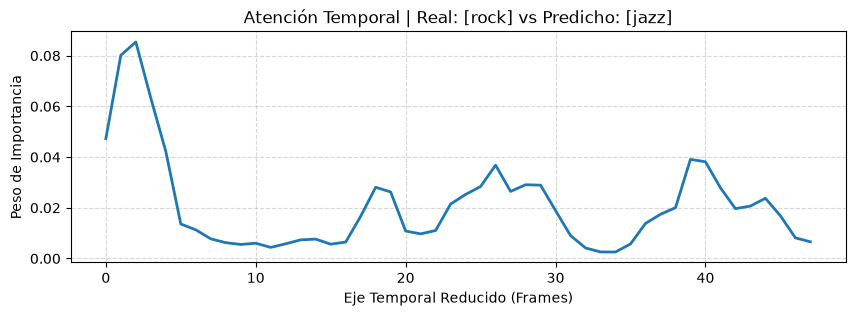


🎵 Canción 3:
   • Género Real:    metal
   • Género Predicho: metal
   • Resultado:      ¡Correcto! ✅


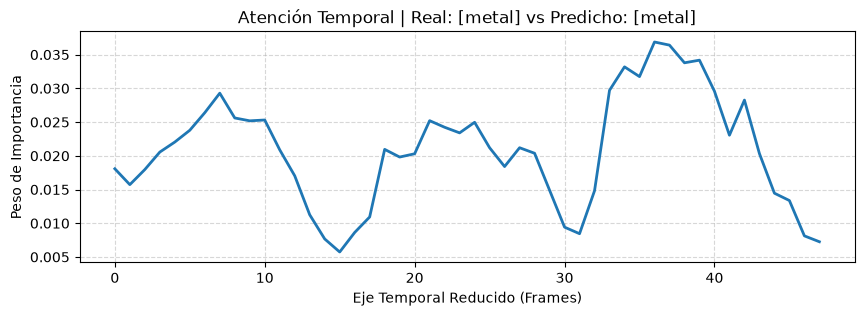


🎵 Canción 4:
   • Género Real:    metal
   • Género Predicho: metal
   • Resultado:      ¡Correcto! ✅


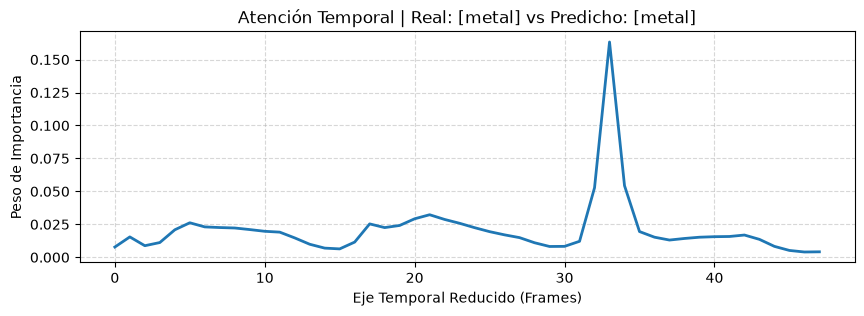


🎵 Canción 5:
   • Género Real:    hiphop
   • Género Predicho: hiphop
   • Resultado:      ¡Correcto! ✅


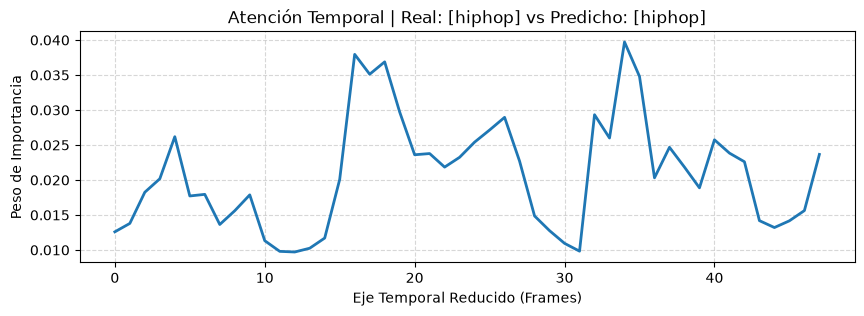


🎵 Canción 6:
   • Género Real:    pop
   • Género Predicho: pop
   • Resultado:      ¡Correcto! ✅


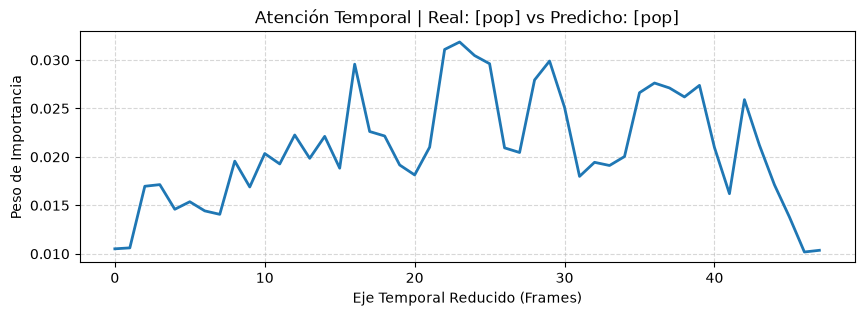


🎵 Canción 7:
   • Género Real:    jazz
   • Género Predicho: jazz
   • Resultado:      ¡Correcto! ✅


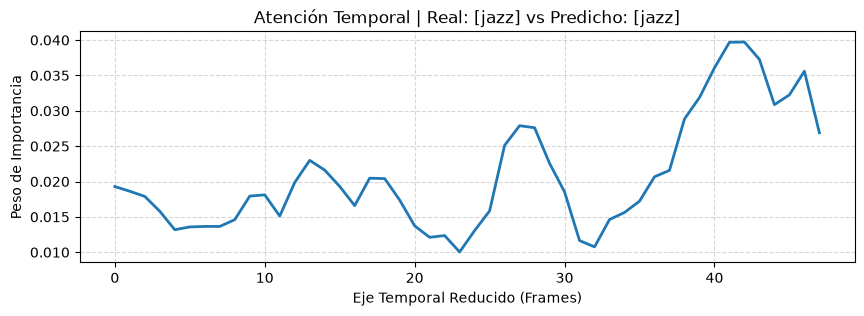


🎵 Canción 8:
   • Género Real:    jazz
   • Género Predicho: jazz
   • Resultado:      ¡Correcto! ✅


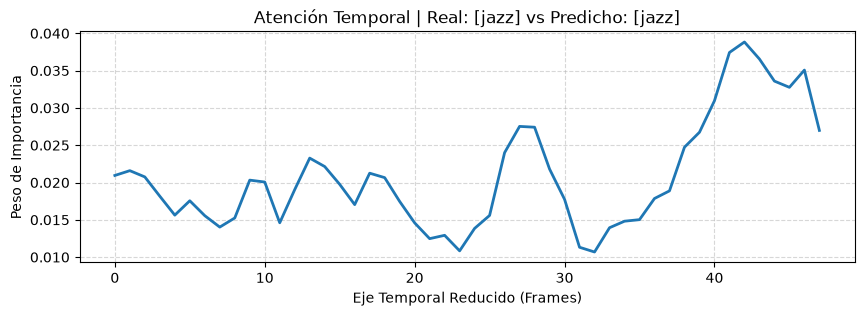

In [9]:
import matplotlib.pyplot as plt
import torch
import os

# Intentar cargar los mejores pesos guardados durante el entrenamiento
if os.path.exists(pesos_modelos['LSTM']):
    print(f"🔄 Cargando los mejores pesos del modelo LSTM ('{pesos_modelos['LSTM']}')...")
    model.load_state_dict(torch.load(pesos_modelos['LSTM'], map_location=device))
else:
    print("⚠️ No se encontraron los pesos de la LSTM, se usará el estado actual del modelo.")

model.eval()
correct = 0
total = 0

# --- 1. EVALUACIÓN GLOBAL (Precisión en todo el set de validación) ---
print("⏳ Evaluando el set de validación (esto puede tomar un momento en CPU)...\n")
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs, _ = model(inputs)

        # Obtener la clase predicha (la de mayor probabilidad)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"🎯 Precisión Total en Validación: {accuracy:.2f}% ({correct}/{total} canciones correctas)\n")
print("="*50)
print("📊 DETALLE DE CANCIONES Y SUS GRÁFICOS DE ATENCIÓN:")
print("="*50)

# --- 2. EVALUACIÓN DETALLADA Y VISUAL (Primer batch de validación) ---
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs, attention_weights = model(inputs)

        _, predicted = torch.max(outputs, 1)

        # Iterar sobre las canciones de este batch
        for i in range(inputs.size(0)):
            pred_idx = predicted[i].item()
            true_idx = labels[i].item()

            # Traducir índices a nombres de géneros
            pred_genre = class_names[pred_idx]
            true_genre = class_names[true_idx]

            print(f"\n🎵 Canción {i+1}:")
            print(f"   • Género Real:    {true_genre}")
            print(f"   • Género Predicho: {pred_genre}")

            if pred_idx == true_idx:
                print("   • Resultado:      ¡Correcto! ✅")
            else:
                print("   • Resultado:      Incorrecto ❌")

            # attention_weights tiene forma [Batch, Reduced_Time, 1]
            weights_np = attention_weights[i].cpu().squeeze().numpy()

            # Graficar los momentos a los que la red prestó atención
            plt.figure(figsize=(10, 3))
            plt.plot(weights_np, color='tab:blue', linewidth=2)
            plt.title(f"Atención Temporal | Real: [{true_genre}] vs Predicho: [{pred_genre}]")
            plt.xlabel("Eje Temporal Reducido (Frames)")
            plt.ylabel("Peso de Importancia")
            plt.grid(True, linestyle='--', alpha=0.5)
            plt.show()

        break  # Rompemos el loop para mostrar solo las canciones del primer batch

🔍 Buscando y analizando errores de clasificación en el conjunto de validación...

❌ Caso de Error #1:
   • Género Real:    ROCK
   • Género Predicho: JAZZ


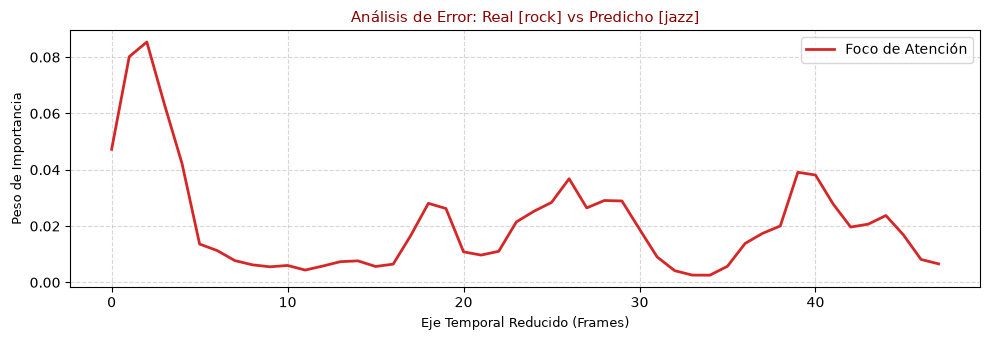

❌ Caso de Error #2:
   • Género Real:    COUNTRY
   • Género Predicho: ROCK


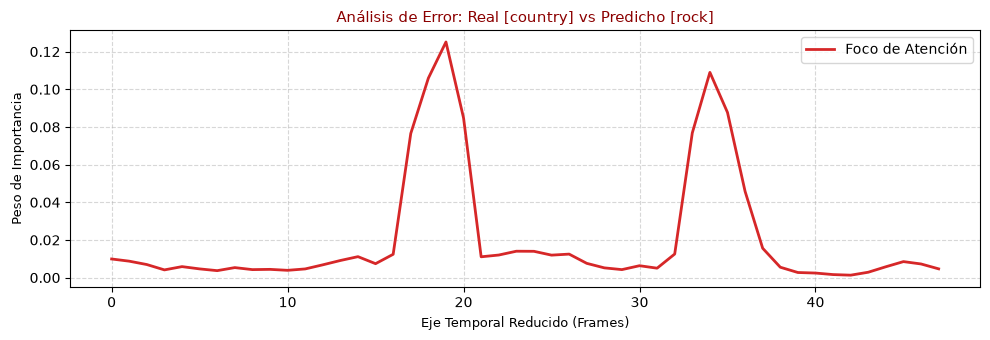

❌ Caso de Error #3:
   • Género Real:    ROCK
   • Género Predicho: REGGAE


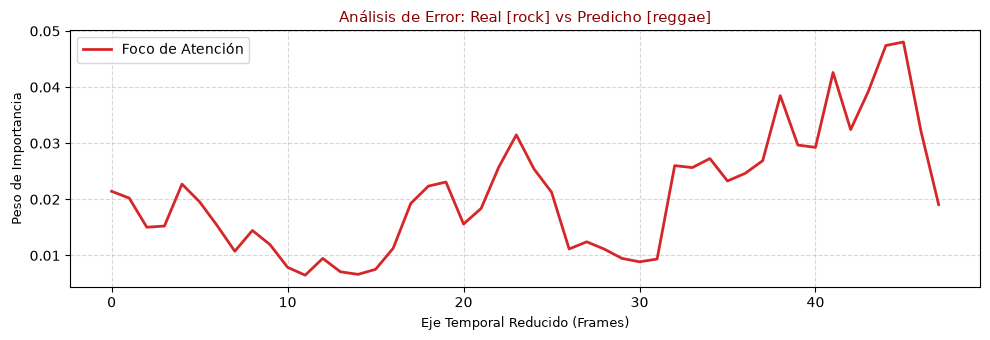

❌ Caso de Error #4:
   • Género Real:    ROCK
   • Género Predicho: POP


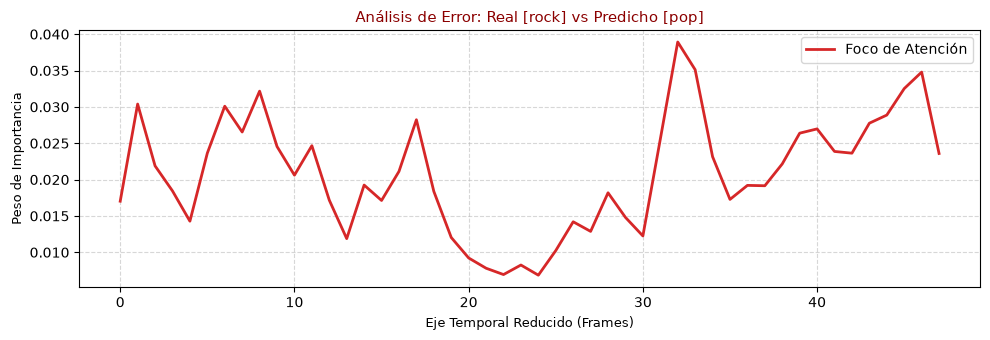

❌ Caso de Error #5:
   • Género Real:    JAZZ
   • Género Predicho: BLUES


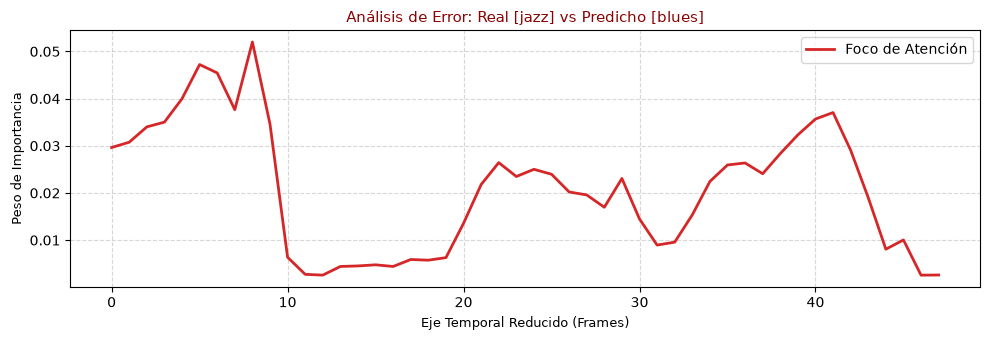

In [10]:
import matplotlib.pyplot as plt
import torch

model.eval()
error_count = 0
max_errors_to_show = 5

print("🔍 Buscando y analizando errores de clasificación en el conjunto de validación...\n")

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs, attention_weights = model(inputs)

        _, predicted = torch.max(outputs, 1)

        for i in range(inputs.size(0)):
            pred_idx = predicted[i].item()
            true_idx = labels[i].item()

            # Solo nos interesan las predicciones incorrectas
            if pred_idx != true_idx:
                error_count += 1
                pred_genre = class_names[pred_idx]
                true_genre = class_names[true_idx]

                print(f"❌ Caso de Error #{error_count}:")
                print(f"   • Género Real:    {true_genre.upper()}")
                print(f"   • Género Predicho: {pred_genre.upper()}")

                # Extraer pesos de atención para este audio específico
                weights_np = attention_weights[i].cpu().squeeze().numpy()

                # Graficar curva de atención temporal
                plt.figure(figsize=(10, 3.5))
                plt.plot(weights_np, color='tab:red', linewidth=2, label='Foco de Atención')
                plt.title(f"Análisis de Error: Real [{true_genre}] vs Predicho [{pred_genre}]", fontsize=11, color='darkred')
                plt.xlabel("Eje Temporal Reducido (Frames)", fontsize=9)
                plt.ylabel("Peso de Importancia", fontsize=9)
                plt.grid(True, linestyle='--', alpha=0.5)
                plt.legend()
                plt.tight_layout()
                plt.show()

                if error_count >= max_errors_to_show:
                    break
        if error_count >= max_errors_to_show:
            break

if error_count == 0:
    print("🎉 ¡Increíble! El modelo clasificó correctamente todas las canciones de este lote.")

## Evaluación del modelo

* Se utilizan los resultados sobre el dataset de test

===== RNN clásica =====
Accuracy final (test): 72.00%
F1 macro final (test): 71.81%



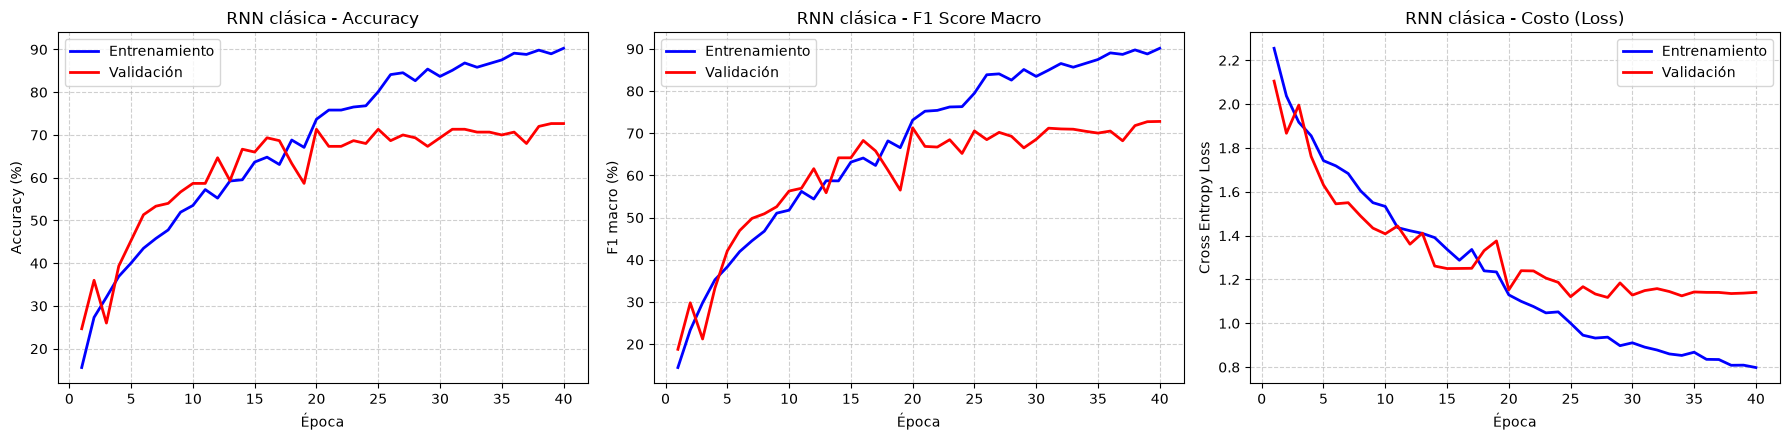

              precision    recall  f1-score   support

       blues      0.611     0.733     0.667        15
   classical      0.812     0.867     0.839        15
     country      0.579     0.733     0.647        15
       disco      0.636     0.467     0.538        15
      hiphop      0.667     0.667     0.667        15
        jazz      0.688     0.733     0.710        15
       metal      0.875     0.933     0.903        15
         pop      0.750     0.800     0.774        15
      reggae      0.909     0.667     0.769        15
        rock      0.750     0.600     0.667        15

    accuracy                          0.720       150
   macro avg      0.728     0.720     0.718       150
weighted avg      0.728     0.720     0.718       150



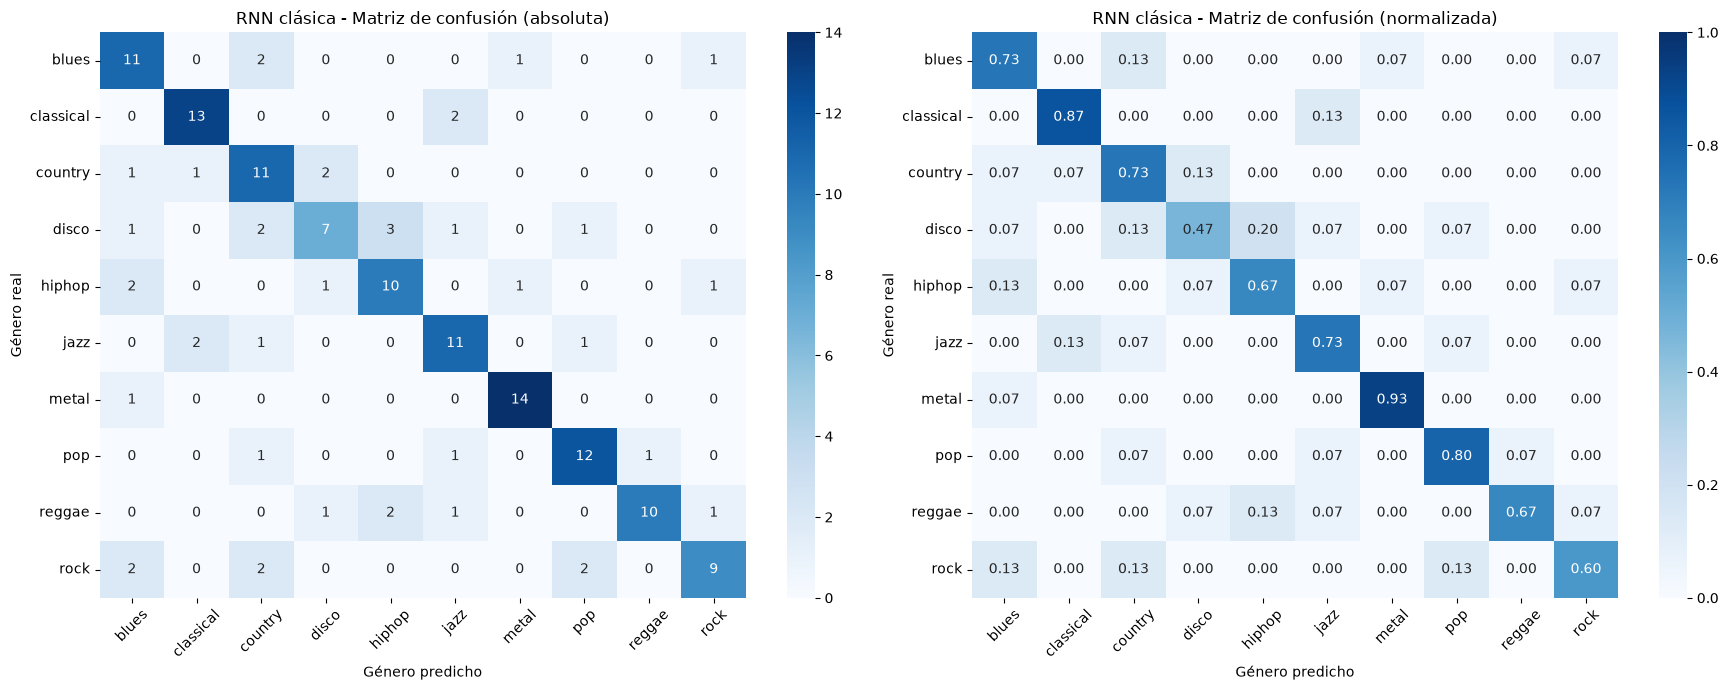

===== LSTM =====
Accuracy final (test): 72.00%
F1 macro final (test): 70.52%



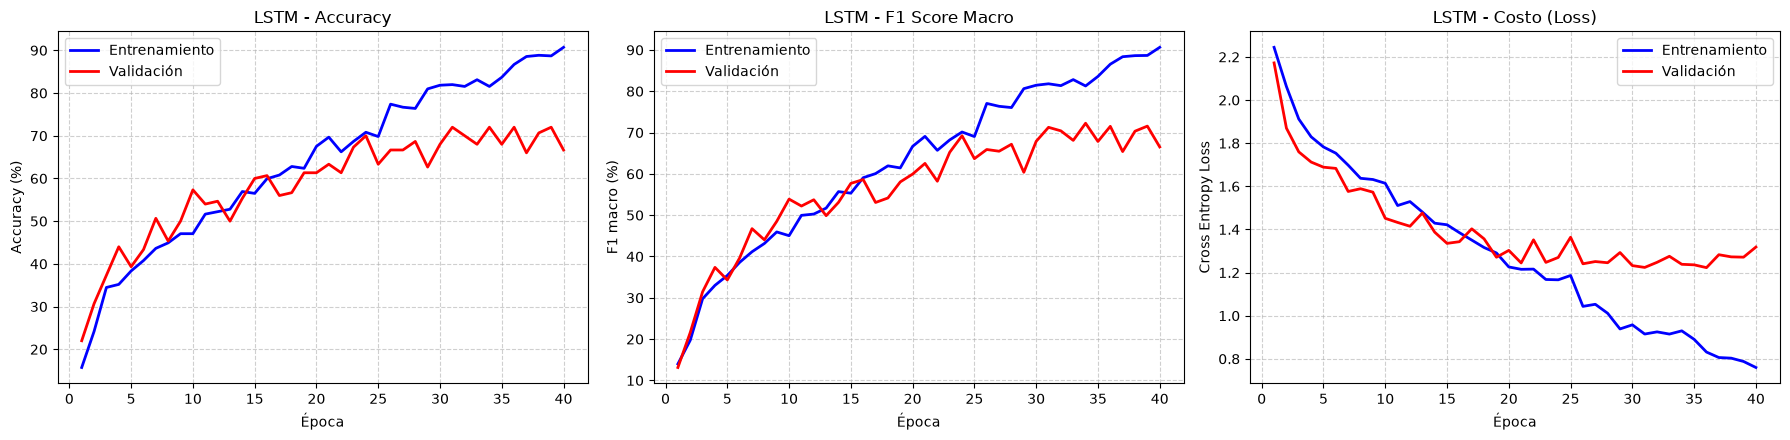

              precision    recall  f1-score   support

       blues      0.706     0.800     0.750        15
   classical      0.867     0.867     0.867        15
     country      0.733     0.733     0.733        15
       disco      0.545     0.400     0.462        15
      hiphop      0.619     0.867     0.722        15
        jazz      0.778     0.933     0.848        15
       metal      0.929     0.867     0.897        15
         pop      0.700     0.933     0.800        15
      reggae      0.714     0.333     0.455        15
        rock      0.583     0.467     0.519        15

    accuracy                          0.720       150
   macro avg      0.717     0.720     0.705       150
weighted avg      0.717     0.720     0.705       150



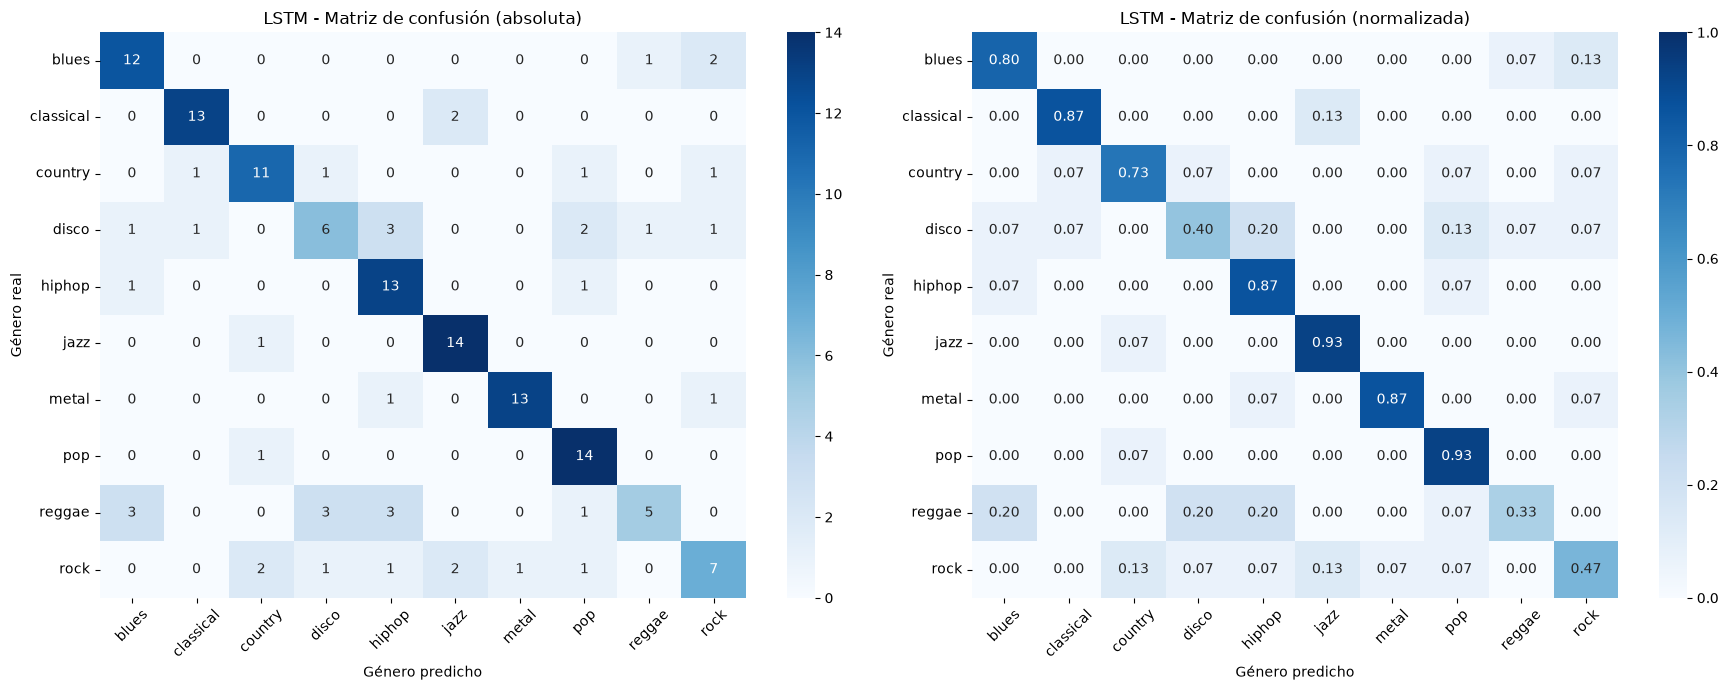

,Accuracy test (%),F1 macro test (%),Accuracy val (%),Loss val (mejor época),Parámetros
RNN clásica,72.0,71.81,72.67,1.1180,734363.0
LSTM,72.0,70.52,72.00,1.2229,1917083.0


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def curva(ax, train, val, titulo, ylabel):
    ep = range(1, len(train) + 1)
    ax.plot(ep, train, 'b-', label='Entrenamiento', linewidth=2)
    ax.plot(ep, val, 'r-', label='Validación', linewidth=2)
    ax.set_title(titulo); ax.set_xlabel('Época'); ax.set_ylabel(ylabel)
    ax.grid(True, linestyle='--', alpha=0.6); ax.legend()

def evaluar_modelo(nombre, modelo, pesos, hist, resultados):
    """Evalúa un modelo en TEST con los mejores pesos (elegidos por validación) y guarda las métricas en `resultados`.
    hist: dict con train_loss, val_loss, train_acc, val_acc, train_f1, val_f1 (por época)."""
    modelo.load_state_dict(torch.load(pesos, map_location=device))
    y_true, y_pred = predecir(modelo, test_loader)
    yv_true, yv_pred = predecir(modelo, val_loader)

    acc = 100 * accuracy_score(y_true, y_pred)
    f1 = 100 * f1_score(y_true, y_pred, average='macro')
    acc_val = 100 * accuracy_score(yv_true, yv_pred)
    print(f"===== {nombre} =====")
    print(f"Accuracy final (test): {acc:.2f}%")
    print(f"F1 macro final (test): {f1:.2f}%\n")

    # Evolución por época: accuracy, F1 macro y loss
    fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
    curva(axs[0], hist['train_acc'], hist['val_acc'], f'{nombre} - Accuracy', 'Accuracy (%)')
    curva(axs[1], hist['train_f1'], hist['val_f1'], f'{nombre} - F1 Score Macro', 'F1 macro (%)')
    curva(axs[2], hist['train_loss'], hist['val_loss'], f'{nombre} - Costo (Loss)', 'Cross Entropy Loss')
    plt.tight_layout(); plt.show()

    # Classification report por clase
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

    # Matrices de confusión: absoluta y normalizada por fila
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = confusion_matrix(y_true, y_pred, normalize='true')
    fig, axs = plt.subplots(1, 2, figsize=(18, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axs[0])
    axs[0].set_title(f'{nombre} - Matriz de confusión (absoluta)')
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, xticklabels=class_names, yticklabels=class_names, ax=axs[1])
    axs[1].set_title(f'{nombre} - Matriz de confusión (normalizada)')
    for ax in axs:
        ax.set_xlabel('Género predicho'); ax.set_ylabel('Género real')
        ax.tick_params(axis='x', rotation=45)
    plt.tight_layout(); plt.show()

    resultados[nombre] = {
        'Accuracy test (%)': round(acc, 2),
        'F1 macro test (%)': round(f1, 2),
        'Accuracy val (%)': round(acc_val, 2),
        'Loss val (mejor época)': round(min(hist['val_loss']), 4),
        'Parámetros': sum(p.numel() for p in modelo.parameters()),
    }

resultados = {}
for nombre in ['RNN clásica', 'LSTM']:
    evaluar_modelo(nombre, modelos[nombre], pesos_modelos[nombre], historiales[nombre], resultados)

# Tabla comparativa de ambos modelos
tabla = pd.DataFrame(resultados).T
display(tabla)

## Análisis comparativo por género

* Evaluamos si las equivocaciones son parejas en todos los géneros

Géneros más débiles en RNN clásica: rock (F1=0.452), blues (F1=0.600), country (F1=0.667)
Géneros más débiles en LSTM: rock (F1=0.429), disco (F1=0.593), reggae (F1=0.593)


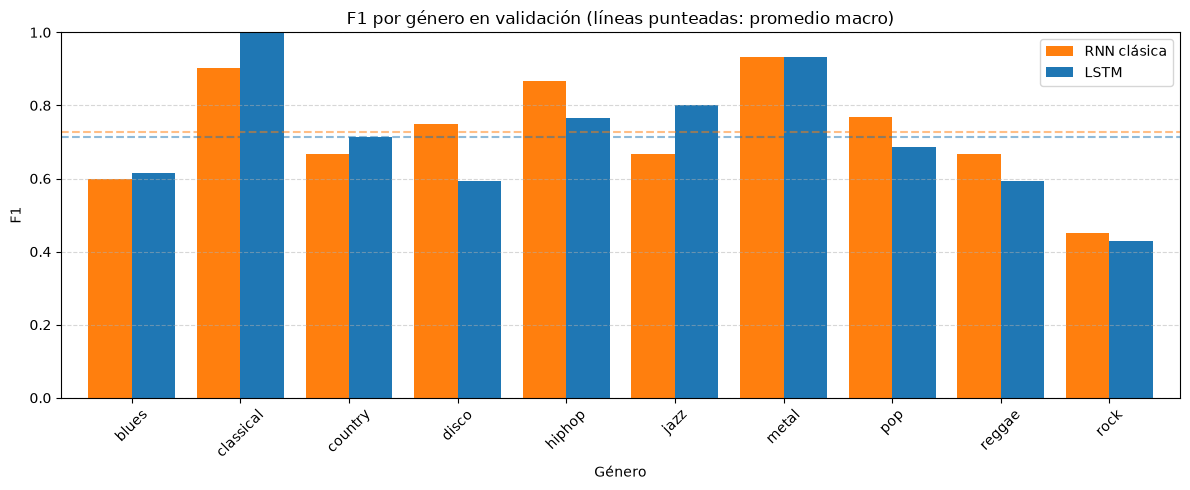

,ΔF1 (LSTM − RNN)
Género,
blues,+0.015
classical,+0.097
country,+0.048
disco,-0.157
hiphop,-0.102
jazz,+0.133
metal,+0.000
pop,-0.084
reggae,-0.074


In [12]:
# ============================================================
# CUADRO COMPARATIVO POR GÉNERO (RNN clásica vs LSTM) - validación
# ============================================================
from sklearn.metrics import precision_recall_fscore_support

nombres = ['RNN clásica', 'LSTM']
filas = {}
for nombre in nombres:
    modelos[nombre].load_state_dict(torch.load(pesos_modelos[nombre], map_location=device))
    y_t, y_p = predecir(modelos[nombre], val_loader)
    p, r, f, s = precision_recall_fscore_support(y_t, y_p, labels=range(len(class_names)), zero_division=0)
    for i, g in enumerate(class_names):
        filas.setdefault(g, {})
        filas[g].update({(nombre, 'Precisión'): p[i], (nombre, 'Recall'): r[i], (nombre, 'F1'): f[i]})
        filas[g][('', 'Soporte')] = int(s[i])

comp = pd.DataFrame(filas).T
comp.columns = pd.MultiIndex.from_tuples(comp.columns)
comp.index.name = 'Género'

# Géneros más débiles: los 3 con menor F1 en cada modelo (rojo) y el peor por modelo (rojo intenso)
def resaltar(df):
    est = pd.DataFrame('', index=df.index, columns=df.columns)
    for nombre in nombres:
        f1 = df[(nombre, 'F1')]
        for g in f1.nsmallest(3).index:
            est.loc[g, (nombre, 'F1')] = 'background-color: #f8b4b4; color: #7a0000; font-weight: bold'
        est.loc[f1.idxmin(), (nombre, 'F1')] = 'background-color: #e53935; color: white; font-weight: bold'
    return est

metricas = [c for c in comp.columns if c[1] != 'Soporte']
# Fila resumen con macro promedio
macro = {c: comp[c].mean() for c in metricas}
macro[('', 'Soporte')] = int(comp[('', 'Soporte')].sum())
comp.loc['MACRO PROMEDIO'] = pd.Series(macro)

display(comp.style.format({c: '{:.3f}' for c in metricas} | {('', 'Soporte'): '{:.0f}'})
        .apply(resaltar, axis=None)
        .set_caption('Métricas por género en validación (rojo claro: 3 peores F1 de cada modelo; rojo intenso: el peor)'))

# Diferencia de F1 por género (LSTM - RNN) y peores géneros
datos = comp.drop(index='MACRO PROMEDIO')
dif = (datos[('LSTM', 'F1')] - datos[('RNN clásica', 'F1')]).rename('ΔF1 (LSTM − RNN)')
for nombre in nombres:
    peores = datos[(nombre, 'F1')].nsmallest(3)
    print(f"Géneros más débiles en {nombre}: " + ', '.join(f'{g} (F1={v:.3f})' for g, v in peores.items()))

# Gráfico de barras agrupadas: F1 por género
ax = datos[[(n, 'F1') for n in nombres]].set_axis(nombres, axis=1).plot.bar(figsize=(12, 5), width=0.8, color=['tab:orange', 'tab:blue'])
ax.axhline(datos[('LSTM', 'F1')].mean(), color='tab:blue', ls='--', alpha=0.5)
ax.axhline(datos[('RNN clásica', 'F1')].mean(), color='tab:orange', ls='--', alpha=0.5)
ax.set_title('F1 por género en validación (líneas punteadas: promedio macro)')
ax.set_ylabel('F1'); ax.set_ylim(0, 1); ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
display(dif.to_frame().style.format('{:+.3f}').background_gradient(cmap='RdYlGn', vmin=-0.3, vmax=0.3))

## "Estabilidad" de los modelos

* Comparamos las métricas en cada una de las corridas

Media ± desviación estándar sobre 5 seeds


,Acc test (%),F1 macro test (%),Acc val (%),Parámetros
RNN clásica,71.60 ± 5.05,71.44 ± 5.32,71.07 ± 4.73,734363
LSTM,72.67 ± 3.13,71.67 ± 3.46,70.40 ± 1.67,1917083


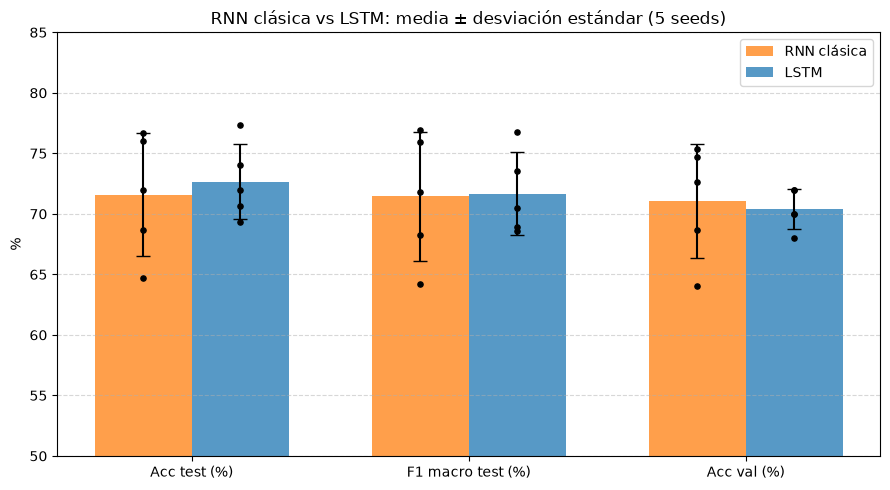

In [13]:
from sklearn.metrics import precision_recall_fscore_support

nombres = ['RNN clásica', 'LSTM']
pred_test = {n: [] for n in nombres}   # lista de (y_true, y_pred) por seed
filas = []
for n in nombres:
    for r in runs[n]:
        r['model'].load_state_dict(torch.load(r['pesos'], map_location=device))
        yt, yp = predecir(r['model'], test_loader)
        pred_test[n].append((yt, yp))
        filas.append({'Modelo': n, 'Seed': r['seed'],
                      'Acc test (%)': 100 * accuracy_score(yt, yp),
                      'F1 macro test (%)': 100 * f1_score(yt, yp, average='macro'),
                      'Acc val (%)': r['val_acc']})
por_seed = pd.DataFrame(filas)

# Tabla comparativa final: media ± std sobre las seeds
params = {n: sum(p.numel() for p in runs[n][0]['model'].parameters()) for n in nombres}
final = {}
for n in nombres:
    d = por_seed[por_seed['Modelo'] == n]
    final[n] = {c: f"{d[c].mean():.2f} ± {d[c].std():.2f}" for c in ['Acc test (%)', 'F1 macro test (%)', 'Acc val (%)']}
    final[n]['Parámetros'] = params[n]
print(f"Media ± desviación estándar sobre {len(SEEDS)} seeds")
display(pd.DataFrame(final).T)

# Gráfico de barras con error (std entre seeds) de la tabla anterior; los puntos son cada seed
metricas = ['Acc test (%)', 'F1 macro test (%)', 'Acc val (%)']
x = np.arange(len(metricas)); ancho = 0.35
fig, ax = plt.subplots(figsize=(9, 5))
for i, (n, color) in enumerate(zip(nombres, ['tab:orange', 'tab:blue'])):
    d = por_seed[por_seed['Modelo'] == n]
    pos = x + (i - 0.5) * ancho
    ax.bar(pos, [d[c].mean() for c in metricas], ancho, yerr=[d[c].std() for c in metricas],
           capsize=5, color=color, alpha=0.75, label=n)
    for j, c in enumerate(metricas):
        ax.scatter(np.full(len(d), pos[j]), d[c], color='black', s=14, zorder=3)
ax.set_xticks(x); ax.set_xticklabels(metricas)
ax.set_ylabel('%'); ax.set_ylim(50, 85); ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_title(f'RNN clásica vs LSTM: media ± desviación estándar ({len(SEEDS)} seeds)')
ax.legend(); plt.tight_layout(); plt.show()

## Resumen de los modelos

* La arquitectura de ambos modelos es la misma, solo cambia la recurrencia. LSTM tiene 4 conjuntos de pesos por capa, la RNN tiene uno

| Bloque | Detalle |
| --- | --- |
| Entrada | Mel-espectrograma 1×128×777 (3 trozos con Hann) |
| CNN | 4 bloques residuales (16→32→64→128), cada uno con 2 conv 3×3, BatchNorm y shortcut 1×1 |
| Pooling y regularización | MaxPool 2×2 tras cada bloque, con Dropout2d de 0.1 / 0.1 / 0.2 / 0.2 |
| Recurrencia | 2 capas bidireccionales, hidden 128 (salida 256), dropout 0.3 entre capas; RNN con tanh o LSTM |
| Atención | Temporal: softmax sobre ~48 pasos, vector de contexto de 256 |
| Clasificador | Linear 256→128, ReLU, Dropout 0.3, Linear 128→10 |

## Conclusiones

* No podemos asegurar que un modelo es mejor que el otro basados en el pre-procesamiento de datos que realizamos y las corridas con las 5 semillas.

* Realizamos pruebas con las muestras originales (30 segundos), solo los primeros 10 segundos, concatenación de 0-3s + 13.5-16.5s + 27-30s y la misma concatenación con ventana Hanning aplicada a cada segmento antes de concatenar. Los resultados obtenidos cambiaron bastante entre corridas, sin aumentar el tiempo de procesamiento.

* La LSTM parece ser mas estable desde el punto de vista de métricas relevantes en test, que tienen baja dispersión considerando las 5 corridas. Los valores de dispersión indican que el trabajo se podría beneficiar con mas corridas para podes sacar conclusiones mas sólidas.

* La RNN es un modelo mucho mas liviano (734 mil parámetros contra 1.9 millones de la LSTM) y parece tener un rendimiento similar a la LSTM, aunque los resultados obtenidos son menos confiables por la dispersión.

* Ambos modelos se equivocan mucho con los géneros Rock (RNN lo confunde con Blues y LSTM con Country) y Reggae (se confunde con Hip Hop y Disco mayormente). Como el pre-procesamiento es común a ambos modelos, un trabajo futuro podría incluir explorar qué características de éstos géneros hacen que los modelos se confundan y agregar pre-procesamiento o features extra enfocados en mejorar éstos errores.

* Los gráficos de atención (LSTM) en las predicciónes incorrectas muestran:
    * En el error Metal - Rock la gráfica sigue la ventana de Hanning aplicada a los 3 segmentos, con lo cual el modelo utilizó información de los 3 segmentos para predecir y posiblemente falló poque los géneros tienen características similares.
    * Parecen darle mucha menos importancia a al menos 1 segmento. Esto indica que se podría trabajar mas en el pre-procesamiento para mejorar resultados.